# IndiKit derivatives vs the base library

Nine organizations run indicator libraries derived from (or analogous to) **www.indikit.net** — "the base". This notebook measures how each one diverged from it:

- which base indicators they kept **identical**, which they **modified** (rewording, adaptation), which they **omitted**, and what they **added** of their own;
- how they reorganized the **sector taxonomy**;
- how the **wording** of shared indicators was adapted to each organization's needs.

Uses the scraped snapshots in `data/` (produced by `data_analysis.ipynb` — no scraping here). All tables are also written to `comparison_base/`.

**Caveat:** Helvetas and Save the Children run fully custom libraries (0% slug/title overlap, different templates). They are included, but can only be matched to the base via embeddings — for these two, "matches" mean *topical similarity*, not confirmed derivation.

In [1]:
import json
import re
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

BASE = "www_indikit_net"

frames = {p.parent.name: pd.read_json(p) for p in sorted(Path("data").glob("*/indicators.json"))}
DOMAINS = sorted((d for d in frames if d != BASE), key=lambda d: -len(frames[d]))
base_df = frames[BASE]

OUT = Path("comparison_base")
OUT.mkdir(exist_ok=True)


def short(domain):
    # display name: indicators_savethechildren_net -> savethechildren
    return domain.replace("indicators_", "").replace("_indikit_net", "").replace("_net", "")


# chart style (dataviz reference palette, light mode)
SURFACE, INK, INK2, MUTED = "#fcfcfb", "#0b0b0b", "#52514e", "#898781"
GRID, BASELINE = "#e1e0d9", "#c3c2b7"
C1, C2, C3 = "#2a78d6", "#1baf7a", "#eda100"  # categorical slots 1-3: blue, aqua, yellow
SEQ_BLUES = ["#cde2fb", "#b7d3f6", "#9ec5f4", "#86b6ef", "#6da7ec", "#5598e7",
             "#3987e5", "#2a78d6", "#256abf", "#1c5cab", "#184f95", "#104281", "#0d366b"]

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": BASELINE, "axes.labelcolor": INK2, "text.color": INK,
    "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False, "axes.spines.left": False,
    "axes.titlelocation": "left", "axes.titlecolor": INK, "axes.titlesize": 12,
    "legend.frameon": False, "font.family": "sans-serif", "font.size": 10,
})

print(f"base: {len(base_df)} indicators | comparison domains: {[short(d) for d in DOMAINS]}")

base: 518 indicators | comparison domains: ['adra', 'irw', 'zoa', 'tearfund', 'savethechildren', 'whh', 'helvetas', 'tdh', 'winrock']


In [2]:
# Overview — size, sectors and template family per site.
# Sites built on the IndiKit engine share the "How to Collect..." section verbatim.
CLONE_MARKER = "section:How to Collect and Analyse the Required Data"

overview = pd.DataFrame(
    {
        "indicators": len(df),
        "sectors": df["sector"].nunique(),
        "template": "IndiKit clone" if CLONE_MARKER in df.columns else "custom",
        "size_vs_base": round(len(df) / len(base_df), 2),
    }
    for df in (frames[d] for d in [BASE] + DOMAINS)
).set_axis([short(d) for d in [BASE] + DOMAINS])
overview

,indicators,sectors,template,size_vs_base
www,518,77,IndiKit clone,1.00
adra,507,69,IndiKit clone,0.98
irw,480,52,IndiKit clone,0.93
zoa,303,30,IndiKit clone,0.58
tearfund,230,9,IndiKit clone,0.44
savethechildren,179,25,custom,0.35
whh,122,12,IndiKit clone,0.24
helvetas,87,11,custom,0.17
tdh,65,16,custom,0.13
winrock,42,11,IndiKit clone,0.08


## Matching each site's indicators to the base

Three-tier ladder — an indicator is matched at the highest tier that fires:

1. **Exact slug** — same URL slug incl. numeric ID (catches near-clones like ADRA).
2. **Slug text or exact title** — derived sites re-number indicators but usually keep the slug text (`5083-individual-dietary-diversity-score` → `individual-dietary-diversity-score`) or the exact title.
3. **Embedding similarity** — `all-MiniLM-L6-v2` over the meaning-bearing fields (wording / phrasing / purpose / definition / full statement), cosine ≥ cutoff. The only channel available for the custom platforms.

Anything below the cutoff is treated as the organization's **own addition**.

In [3]:
# Normalization helpers + derived columns on every frame
SEMANTIC_PATTERNS = ("wording", "phrasing", "purpose", "definition", "full statement")
WORDING_PATTERNS = ("wording", "phrasing", "full statement")


def text_slug(slug):
    # slug without the numeric ID prefix — derived sites re-number but keep the text
    return re.sub(r"^\d+-", "", str(slug))


def norm(s):
    if not isinstance(s, str):
        return ""
    s = re.sub(r"[^a-z0-9 ]", " ", s.lower())
    return re.sub(r"\s+", " ", s).strip()


LANG_LABELS = {"english", "french", "arabic", "spanish", "portuguese", "français", "francais"}


def english_only(text):
    # Derived sites publish sections multilingually, in several layouts:
    #   block:       "English\nFrench\n<en>\n<fr>"            (zoa, irw, adra)
    #   interleaved: "English:\n<en>\nFrench:\n<fr>"          (whh)
    #   tab residue: "INDICATOR PHRASING\nFrançais\n<en>\n…"  (tearfund)
    # The base is English-only, so reduce every layout to the English text.
    lines = [l.strip() for l in text.split("\n") if l.strip()]
    if lines and lines[0].isupper() and len(lines[0]) < 40:
        lines = lines[1:]  # section-header echo, e.g. "INDICATOR PHRASING"
    is_label = [l.lower().rstrip(":") in LANG_LABELS for l in lines]
    if not any(is_label):
        return "\n".join(lines)
    i0 = is_label.index(True)
    n = 0
    while i0 + n < len(lines) and is_label[i0 + n]:
        n += 1
    head, rest = lines[:i0], lines[i0 + n:]
    if n == 1 and lines[i0].lower().rstrip(":") == "english":
        seg = []
        for k, l in enumerate(rest):
            if is_label[i0 + 1 + k]:
                break
            seg.append(l)
        return "\n".join(head + seg)
    if n == 1:
        # single non-English label: texts follow one per language, English first
        return "\n".join(head + rest[:1])
    per = len(rest) // n if rest and len(rest) % n == 0 else 1
    return "\n".join(head + rest[:per])


def field_text(row, patterns):
    parts = []
    for field, v in row.items():
        if any(p in field.lower() for p in patterns) and isinstance(v, str) and v.strip():
            parts.append(english_only(v.strip()))
    return "\n".join(parts)


for domain, df in frames.items():
    df["text_slug"] = df["slug"].map(text_slug)
    df["norm_title"] = df["title"].map(norm)
    df["wording"] = df.apply(lambda r: field_text(r, WORDING_PATTERNS), axis=1)
    df["canonical"] = df.apply(lambda r: str(r["title"]) + "\n" + field_text(r, SEMANTIC_PATTERNS), axis=1)

# base lookup maps (first occurrence wins on the rare duplicate)
base_by_slug, base_by_textslug, base_by_title = {}, {}, {}
for j, r in base_df.iterrows():
    base_by_slug.setdefault(r["slug"], j)
    base_by_textslug.setdefault(r["text_slug"], j)
    if r["norm_title"]:
        base_by_title.setdefault(r["norm_title"], j)

print(f"base lookups: {len(base_by_slug)} slugs, {len(base_by_textslug)} slug texts, {len(base_by_title)} titles")

base lookups: 517 slugs, 515 slug texts, 515 titles


In [4]:
# Embeddings over canonical text — all domains including the base
from sentence_transformers import SentenceTransformer

model = SentenceTransformer("all-MiniLM-L6-v2")
emb = {
    domain: model.encode(df["canonical"].tolist(), normalize_embeddings=True, show_progress_bar=False)
    for domain, df in frames.items()
}
print({short(d): e.shape for d, e in emb.items()})

{'adra': (507, 384), 'helvetas': (87, 384), 'savethechildren': (179, 384), 'irw': (480, 384), 'tdh': (65, 384), 'tearfund': (230, 384), 'whh': (122, 384), 'winrock': (42, 384), 'www': (518, 384), 'zoa': (303, 384)}


In [5]:
# The matching ladder. Tier 3 assignments are provisional here — the cutoff is
# applied in the next cell after inspecting the similarity distribution.
rows = []
for domain in DOMAINS:
    df = frames[domain]
    sims = emb[domain] @ emb[BASE].T
    best_j = sims.argmax(axis=1)
    for i, row in df.iterrows():
        j, tier = None, None
        if row["slug"] in base_by_slug:
            j, tier = base_by_slug[row["slug"]], 1
        elif row["text_slug"] in base_by_textslug:
            j, tier = base_by_textslug[row["text_slug"]], 2
        elif row["norm_title"] and row["norm_title"] in base_by_title:
            j, tier = base_by_title[row["norm_title"]], 2
        if j is None:
            j, tier = int(best_j[i]), 3
        rows.append({
            "domain": domain, "idx": i, "title": row["title"], "sector": row["sector"],
            "tier": tier, "base_idx": j,
            "base_title": base_df.loc[j, "title"], "base_sector": base_df.loc[j, "sector"],
            "similarity": round(float(sims[i, j]), 3),
            "norm_wording": norm(row["wording"]),
            "norm_base_wording": norm(base_df.loc[j, "wording"]),
        })

matches = pd.DataFrame(rows)
matches.pivot_table(index="domain", columns="tier", aggfunc="size", fill_value=0)

tier,1,2,3
domain,,,
adra_indikit_net,448,1,58
helvetas_indikit_net,0,0,87
indicators_savethechildren_net,0,0,179
irw_indikit_net,0,248,232
tdh_indikit_net,0,0,65
tearfund_indikit_net,0,24,206
whh_indikit_net,0,61,61
winrock_indikit_net,0,1,41
zoa_indikit_net,0,196,107


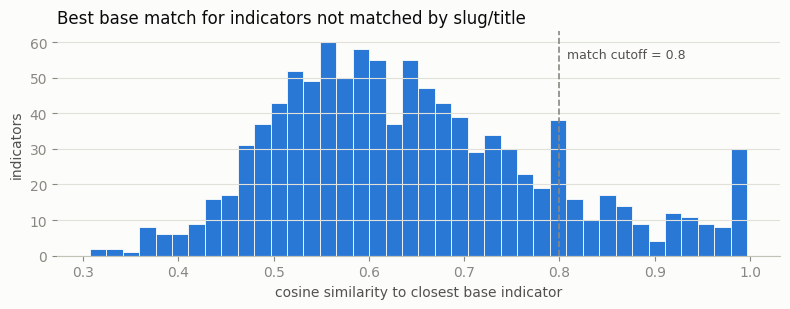

tier,0,1,2,3
domain,,,,
adra_indikit_net,36,448,1,22
helvetas_indikit_net,85,0,0,2
indicators_savethechildren_net,169,0,0,10
irw_indikit_net,165,0,248,67
tdh_indikit_net,65,0,0,0
tearfund_indikit_net,183,0,24,23
whh_indikit_net,42,0,61,19
winrock_indikit_net,41,0,1,0
zoa_indikit_net,87,0,196,20


In [6]:
# Tier-3 cutoff: distribution of best cosine similarity for indicators that
# tiers 1-2 could not match. Above the cutoff = probably the same indicator,
# below = the organization's own addition.
THRESH = 0.80

tier3 = matches[matches["tier"] == 3]
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.hist(tier3["similarity"], bins=40, color=C1, edgecolor=SURFACE, linewidth=0.6)
ax.axvline(THRESH, color=MUTED, linestyle="--", linewidth=1.2)
ax.text(THRESH + 0.008, ax.get_ylim()[1] * 0.88, f"match cutoff = {THRESH}", color=INK2, fontsize=9)
ax.xaxis.grid(False)
ax.set_title("Best base match for indicators not matched by slug/title")
ax.set_xlabel("cosine similarity to closest base indicator")
ax.set_ylabel("indicators")
plt.tight_layout()
plt.show()

# below the cutoff -> tier 0 (no base counterpart)
matches.loc[(matches["tier"] == 3) & (matches["similarity"] < THRESH), "tier"] = 0
matches.loc[matches["tier"] == 0, ["base_title", "base_sector"]] = None
matches.pivot_table(index="domain", columns="tier", aggfunc="size", fill_value=0)

## Classification: identical, modified, added, omitted

Per site, each indicator is classified against the base:

- **identical** — matched, and the indicator wording is character-identical after normalization (derived sites publish wording multilingually, so only the English text is compared);
- **modified** — matched, but the wording (or only the title, for the custom platforms) differs;
- **added** — no base counterpart: the organization's own indicator.

On the base side, **omitted** = base indicators with no match on that site. The custom platforms can never score "identical" (their templates share no wording field with the base), so read their bars as modified-at-best.

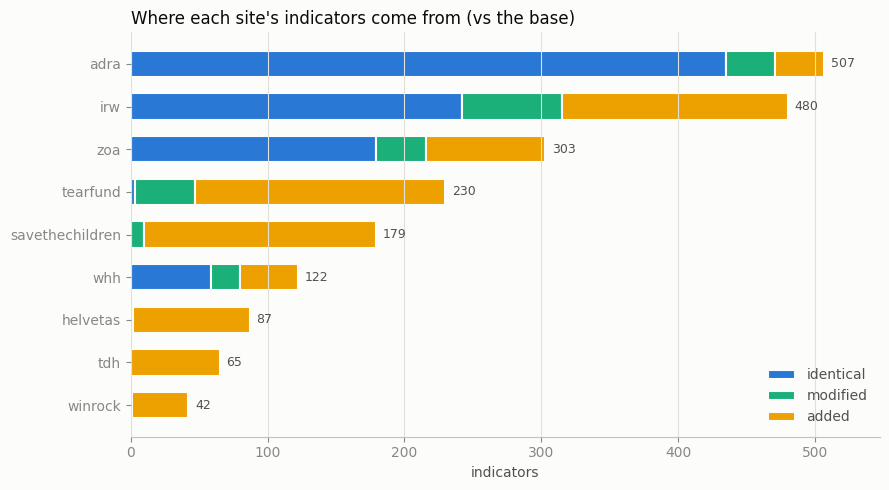

class,identical,modified,added,omitted
domain,,,,
adra_indikit_net,435,36,36,55
irw_indikit_net,242,73,165,219
zoa_indikit_net,179,37,87,314
tearfund_indikit_net,3,44,183,478
indicators_savethechildren_net,0,10,169,508
whh_indikit_net,59,21,42,439
helvetas_indikit_net,0,2,85,516
tdh_indikit_net,0,0,65,518
winrock_indikit_net,0,1,41,517


In [7]:
def classify(m):
    if m["tier"] == 0:
        return "added"
    if m["norm_wording"] and m["norm_wording"] == m["norm_base_wording"]:
        return "identical"
    return "modified"


matches["class"] = matches.apply(classify, axis=1)

class_counts = (
    matches.pivot_table(index="domain", columns="class", aggfunc="size", fill_value=0)
    .reindex(columns=["identical", "modified", "added"], fill_value=0)
    .reindex(DOMAINS)
)
class_counts["omitted"] = [
    len(base_df) - matches[(matches["domain"] == d) & (matches["tier"] > 0)]["base_idx"].nunique()
    for d in class_counts.index
]

matches.drop(columns=["norm_wording", "norm_base_wording"]).to_csv(OUT / "classification.csv", index=False)

order = class_counts[["identical", "modified", "added"]].sum(axis=1).sort_values().index
cc = class_counts.loc[order]
fig, ax = plt.subplots(figsize=(9, 5))
left = np.zeros(len(cc))
for col, color in [("identical", C1), ("modified", C2), ("added", C3)]:
    ax.barh([short(d) for d in order], cc[col].to_numpy(float), left=left,
            height=0.62, color=color, edgecolor=SURFACE, linewidth=1.5, label=col)
    left += cc[col].to_numpy(float)
for y, total in enumerate(left):
    ax.text(total + 5, y, str(int(total)), va="center", color=INK2, fontsize=9)
ax.yaxis.grid(False)
ax.margins(x=0.08)
ax.set_title("Where each site's indicators come from (vs the base)")
ax.set_xlabel("indicators")
ax.legend(loc="lower right", labelcolor=INK2)
plt.tight_layout()
plt.show()

class_counts

## What each organization omits

Retention of each base sector per site: what share of the sector's base indicators has *any* match on that site. Dark column = the site kept the sector nearly whole; light gaps = the sector was dropped or heavily pruned. Only base sectors with ≥ 5 indicators are shown (smaller ones are noise); the excluded remainder is reported below the chart.

showing 55 base sectors (>=5 indicators); 22 smaller sectors (64 indicators) not shown


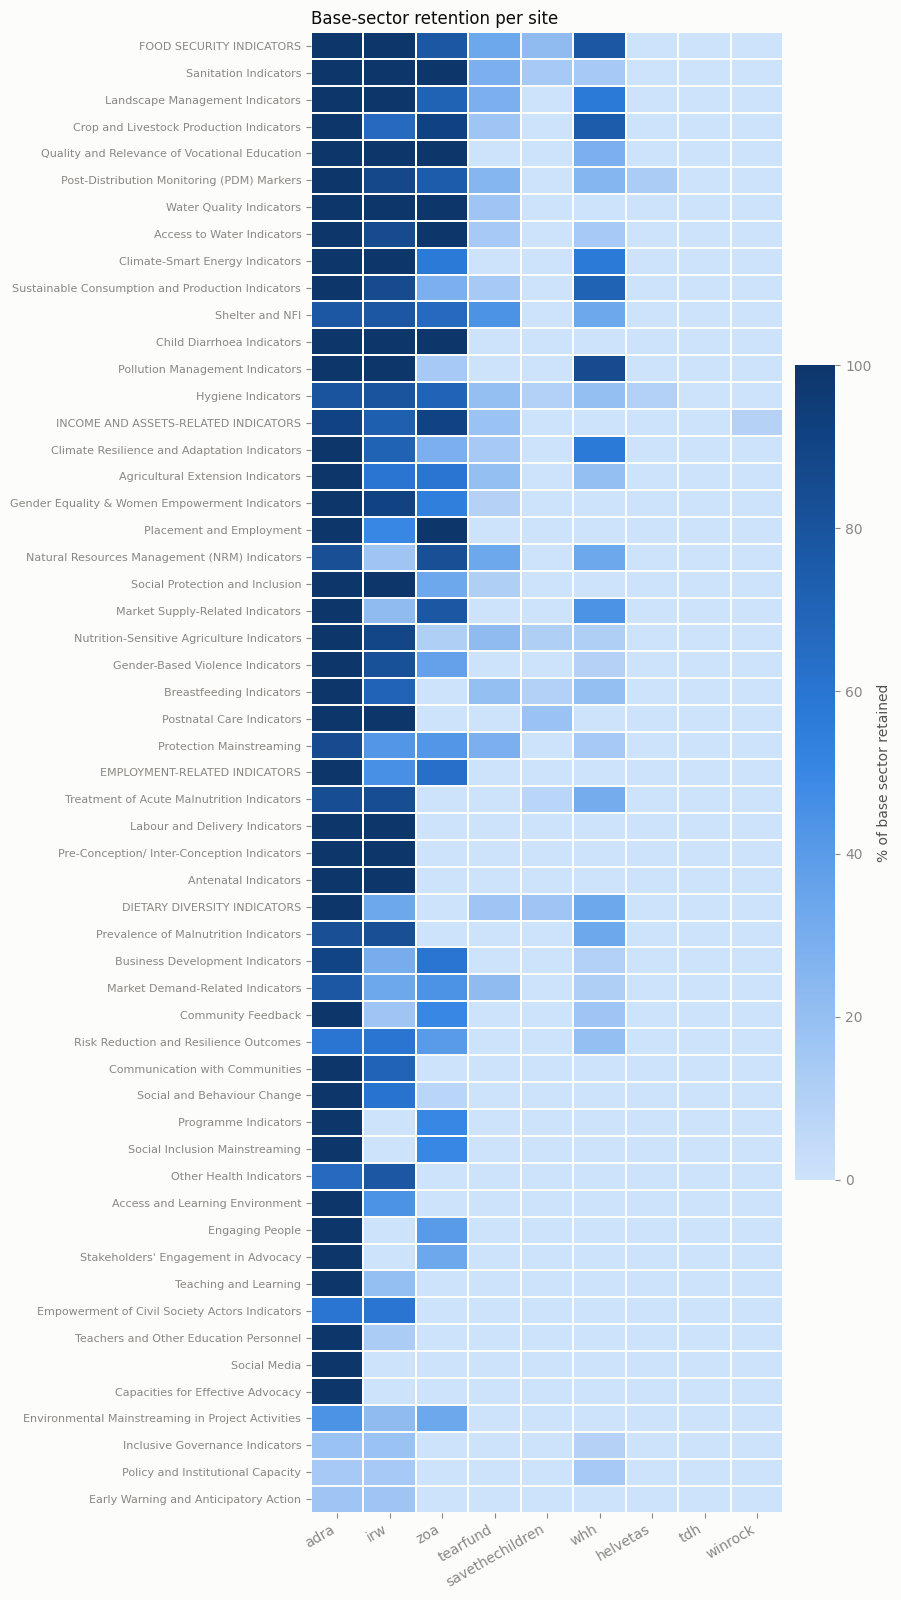

In [8]:
from matplotlib.colors import LinearSegmentedColormap

base_sector_sizes = base_df["sector"].value_counts()
big = base_sector_sizes[base_sector_sizes >= 5]
matched = matches[matches["tier"] > 0]

retention = pd.DataFrame(index=big.index, columns=DOMAINS, dtype=float)
for d in DOMAINS:
    got = matched[matched["domain"] == d]["base_idx"].unique()
    got_sectors = base_df.loc[got, "sector"].value_counts()
    retention[d] = (got_sectors.reindex(big.index).fillna(0) / big * 100).round(1)

retention = retention.loc[retention.mean(axis=1).sort_values(ascending=False).index]
retention.to_csv(OUT / "sector_retention.csv")
n_small = len(base_sector_sizes) - len(big)
print(f"showing {len(big)} base sectors (>=5 indicators); {n_small} smaller sectors "
      f"({base_sector_sizes[base_sector_sizes < 5].sum()} indicators) not shown")

cmap = LinearSegmentedColormap.from_list("seq_blues", SEQ_BLUES)
fig, ax = plt.subplots(figsize=(9, 0.26 * len(retention) + 1.8))
mesh = ax.pcolormesh(retention.to_numpy(float), cmap=cmap, vmin=0, vmax=100,
                     edgecolors=SURFACE, linewidth=1.2)
ax.set_xticks(np.arange(len(retention.columns)) + 0.5)
ax.set_xticklabels([short(d) for d in retention.columns], rotation=30, ha="right")
ax.set_yticks(np.arange(len(retention)) + 0.5)
ax.set_yticklabels(retention.index, fontsize=8)
ax.invert_yaxis()
ax.grid(False)
for spine in ax.spines.values():
    spine.set_visible(False)
ax.set_title("Base-sector retention per site")
cbar = fig.colorbar(mesh, ax=ax, shrink=0.55, pad=0.02)
cbar.set_label("% of base sector retained", color=INK2)
cbar.outline.set_visible(False)
plt.tight_layout()
plt.show()

## Sector re-mapping

Even when an indicator is kept, sites file it under their own taxonomy. For confidently matched pairs (tiers 1-2), how often does the sector name change — and where do ZOA's kept indicators end up?

In [9]:
conf = matches[matches["tier"].isin([1, 2])]

remap_stats = pd.DataFrame(
    {
        "confident_matches": len(sub),
        "base_sectors_covered": sub["base_sector"].nunique(),
        "own_sectors_used": sub["sector"].nunique(),
        "sector_renamed_pct": round(100 * (sub["sector"].map(norm) != sub["base_sector"].map(norm)).mean(), 1)
        if len(sub) else None,
    }
    for sub in (conf[conf["domain"] == d] for d in DOMAINS)
).set_axis([short(d) for d in DOMAINS])
print(remap_stats)

# ZOA example: most common base-sector -> own-sector moves (name actually changed)
zoa = conf[conf["domain"] == "zoa_indikit_net"]
zoa_remap = (
    zoa[zoa["sector"].map(norm) != zoa["base_sector"].map(norm)]
    .groupby(["base_sector", "sector"]).size().rename("indicators")
    .reset_index().sort_values("indicators", ascending=False)
)
zoa_remap.head(15)

                 confident_matches  base_sectors_covered  own_sectors_used  \
adra                           449                    75                67   
irw                            248                    54                46   
zoa                            196                    51                22   
tearfund                        24                    13                 5   
savethechildren                  0                     0                 0   
whh                             61                    24                11   
helvetas                         0                     0                 0   
tdh                              0                     0                 0   
winrock                          1                     1                 1   

                 sector_renamed_pct  
adra                           15.8  
irw                            58.9  
zoa                           100.0  
tearfund                      100.0  
savethechildren              

,base_sector,sector,indicators
19,Crop and Livestock Production Indicators,Agriculture and Natural Resource Management,10
38,INCOME AND ASSETS-RELATED INDICATORS,Income and Employment,9
68,Sanitation Indicators,Sanitation,7
63,Quality and Relevance of Vocational Education,"Skills, Training and Employability",6
32,Gender Equality & Women Empowerment Indicators,Gender Equality,6
34,Hygiene Indicators,Hygiene,5
47,Market Supply-Related Indicators,Market Development,5
58,Post-Distribution Monitoring (PDM) Markers,Process & quality management,5
55,Placement and Employment,"Skills, Training and Employability",5
0,Access to Water Indicators,Water,5


## How wording changes

For confidently matched but **modified** indicators (tiers 1-2, both sides have wording text): how far does the wording drift, and what do the edits look like? Similarity here is a character-level `SequenceMatcher` ratio on normalized wording — 1.0 means identical, ~0.9 means small edits, below ~0.5 usually a full rewrite.

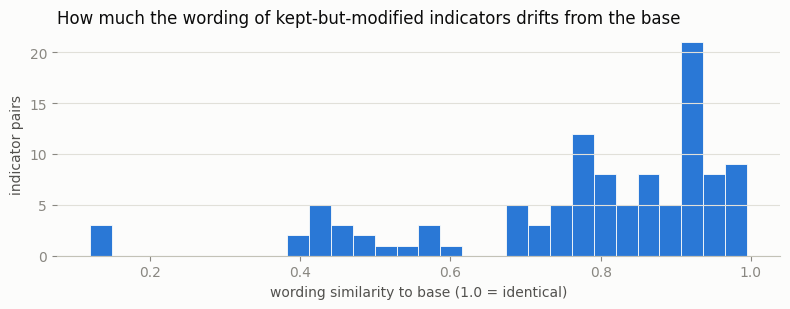

                      pairs  median
domain                             
adra_indikit_net         22    0.86
irw_indikit_net          38    0.84
tearfund_indikit_net     21    0.61
whh_indikit_net          12    0.91
winrock_indikit_net       1    0.68
zoa_indikit_net          16    0.84


In [10]:
from difflib import SequenceMatcher, ndiff

mod = matches[(matches["class"] == "modified") & matches["tier"].isin([1, 2])].copy()
mod = mod[(mod["norm_wording"] != "") & (mod["norm_base_wording"] != "")]
mod["wording_sim"] = [
    round(SequenceMatcher(None, a, b).ratio(), 3)
    for a, b in zip(mod["norm_wording"], mod["norm_base_wording"])
]

fig, ax = plt.subplots(figsize=(8, 3.2))
ax.hist(mod["wording_sim"], bins=30, color=C1, edgecolor=SURFACE, linewidth=0.6)
ax.xaxis.grid(False)
ax.set_title("How much the wording of kept-but-modified indicators drifts from the base")
ax.set_xlabel("wording similarity to base (1.0 = identical)")
ax.set_ylabel("indicator pairs")
plt.tight_layout()
plt.show()

print(mod.groupby("domain")["wording_sim"].agg(pairs="count", median="median").round(2))

In [11]:
# Small-edit example: the word-level diff of a near-identical pair shows *what*
# organizations tweak (target groups, thresholds, terminology).
ex = mod[mod["wording_sim"].between(0.75, 0.97)].sort_values("wording_sim", ascending=False).iloc[0]
print(f"{short(ex['domain'])} | {ex['title']}  (wording similarity {ex['wording_sim']})")
print("\nword-level diff (base -> site):")
for tok in ndiff(ex["norm_base_wording"].split(), ex["norm_wording"].split()):
    if tok[0] in "+-":
        print(" ", tok)

# Heavier adaptations: same indicator, substantially rewritten
print("\n" + "=" * 90)
for _, m in mod[mod["wording_sim"].between(0.35, 0.7)].sort_values("wording_sim").head(3).iterrows():
    print(f"\n{short(m['domain'])} | {m['title']}  (wording similarity {m['wording_sim']})")
    print(f"  BASE : {base_df.loc[m['base_idx'], 'wording'][:300]}")
    print(f"  SITE : {frames[m['domain']].loc[m['idx'], 'wording'][:300]}")

irw | Disaster Preparedness Plan - Implementation  (wording similarity 0.97)

word-level diff (base -> site):
  - number


tearfund | Animal Raising  (wording similarity 0.395)
  BASE : % of target farmers who raise [specify the animal]
  SITE : number of target households who started raising at least one of the promoted types of domestic animals in the course of the project

tearfund | Access to Adequate Shelter  (wording similarity 0.402)
  BASE : number of people having access to basic, safe and dignified shelters solutions
  SITE : Number of targeted households living in adequate shelters which meet shelter standards as defined by the cluster

adra | Perceived Safety  (wording similarity 0.427)
  BASE : % of individuals / target population in a given context reporting an improved feeling of safety (with dignity) by the end of the intervention compared to at the beginning
  SITE : % of the target population who felt safe when accessing and using the [specify: cash / vouchers / …]


## What each organization adds

Indicators with no base counterpart — each organization's own priorities. Grouped by the site's own sectors.

In [12]:
added = matches[matches["class"] == "added"]
added[["domain", "title", "sector", "similarity"]].to_csv(OUT / "added_indicators.csv", index=False)

for d in DOMAINS:
    sub = added[added["domain"] == d]
    top = sub["sector"].value_counts().head(3)
    tops = ", ".join(f"{s} ({n})" for s, n in top.items())
    print(f"{short(d):16s} {len(sub):4d} added | top sectors: {tops}")

added[added["domain"] == "zoa_indikit_net"][["title", "sector", "similarity"]].head(15)

adra               36 added | top sectors: DRR and Resilience (10), Good Governance (7), Water Indicators (3)
irw               165 added | top sectors: Global Results Framework (73), Disaster Risk Reduction and Resilience (10), Social Protection and Inclusion (9)
zoa                87 added | top sectors: Sector specific results of CVA (9), Organisational level indicators (9), Process & quality management (8)
tearfund          183 added | top sectors: Water, sanitation and hygiene (WASH) (55), Gender-based violence (GBV) and psychosocial support (PSS) (30), Peacebuilding (24)
savethechildren   169 added | top sectors: Output Indicators (49), Other Strategy Indicators (46), Institutions with basic drinking water, limited sanitation or hygiene services (12)
whh                42 added | top sectors: Education and Skills Development (10), WASH (7), Civil Society (7)
helvetas           85 added | top sectors: People (42), Frame Condition (11), Partners (8)
tdh                65 added | to

,title,sector,similarity
1000,Average Queuing Time at a Water Point,Water,0.591
1001,Number of People per Water Point,Water,0.603
1008,Water Source Repairs,Water,0.679
1014,Availability of Soap,Hygiene,0.793
1031,Customer Satisfaction,Market Development,0.774
1034,Generation of Employment Opportunities,Income and Employment,0.613
1045,Prevention of Groundwater Contamination by Faeces,Water,0.622
1053,Vulnerability and Capacity Assessment,"Skills, Training and Employability",0.793
1054,Climate Risk Perception,Project level indicators,0.718
1057,Self-Help Groups - Functionality,"Community Engagement, Participation & Advocacy",0.548


## Summary

The nine sites fall into three clear strategies:

- **Near-clone — ADRA**: carries 89% of the base, 435/507 indicators word-for-word identical; only 36 own additions (mostly DRR & Resilience, Good Governance).
- **Curated subsets — IRW, ZOA, WHH**: keep roughly 58% / 39% / 15% of the base, mostly verbatim (242 / 179 / 59 identical), silently omit the rest, and add a substantial own layer (IRW: a 77-indicator Global Results Framework; ZOA: organisational, process-quality and CVA indicators; WHH: education, WASH and civil society). ZOA and WHH re-file **every** kept indicator into their own, much smaller sector taxonomy (ZOA: 22 sectors vs the base's 77) — the content is the base's, the structure is their own.
- **Platform only — Tearfund, Winrock, Helvetas, Save the Children, TdH**: under 8% base coverage; these organizations use (or resemble) the IndiKit engine but publish essentially their own libraries (Tearfund: WASH/GBV/peacebuilding; Winrock: USG standard indicators; Helvetas & SCI: internal results frameworks; TdH: child-protection and health).

Where kept indicators *are* modified, the edits are mostly small (median wording similarity ≈ 0.85 for ADRA/IRW/ZOA): swapped target groups ("farmers" → "households"), added qualifiers ("promoted" types), changed units (% → number), and localized bracketed placeholders — i.e. adaptations to each organization's programming context rather than redefinitions.

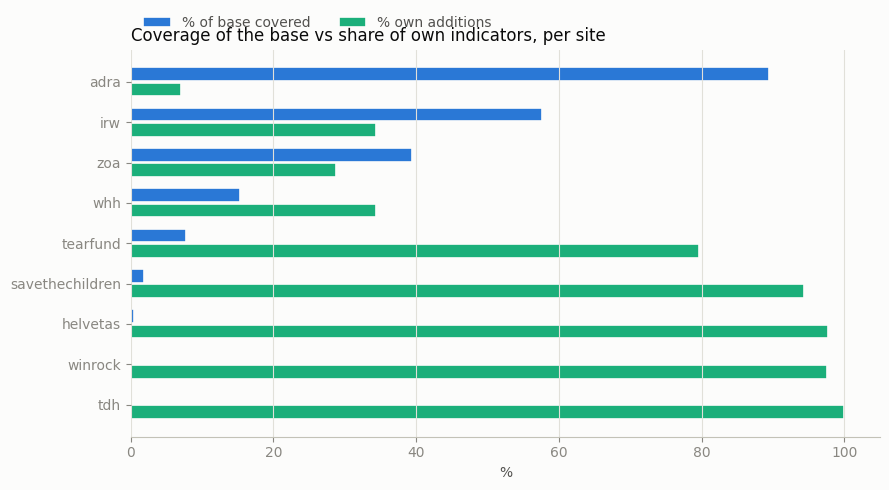

class,indicators,template,identical,modified,added,omitted,base_covered_pct,own_additions_pct
adra,507,clone,435,36,36,55,89.4,7.1
irw,480,clone,242,73,165,219,57.7,34.4
zoa,303,clone,179,37,87,314,39.4,28.7
tearfund,230,clone,3,44,183,478,7.7,79.6
savethechildren,179,custom,0,10,169,508,1.9,94.4
whh,122,clone,59,21,42,439,15.3,34.4
helvetas,87,custom,0,2,85,516,0.4,97.7
tdh,65,custom,0,0,65,518,0.0,100.0
winrock,42,clone,0,1,41,517,0.2,97.6


In [13]:
summary = class_counts.copy()
summary.insert(0, "indicators", [len(frames[d]) for d in summary.index])
summary.insert(1, "template", ["clone" if CLONE_MARKER in frames[d].columns else "custom" for d in summary.index])
summary["base_covered_pct"] = [
    round(100 * matches[(matches["domain"] == d) & (matches["tier"] > 0)]["base_idx"].nunique() / len(base_df), 1)
    for d in summary.index
]
summary["own_additions_pct"] = (100 * summary["added"] / summary["indicators"]).round(1)
summary.index = [short(d) for d in summary.index]
summary.to_csv(OUT / "summary.csv")

s = summary.sort_values("base_covered_pct")
y = np.arange(len(s))
fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(y + 0.19, s["base_covered_pct"], height=0.34, color=C1,
        edgecolor=SURFACE, linewidth=1.2, label="% of base covered")
ax.barh(y - 0.19, s["own_additions_pct"], height=0.34, color=C2,
        edgecolor=SURFACE, linewidth=1.2, label="% own additions")
ax.set_yticks(y)
ax.set_yticklabels(s.index)
ax.yaxis.grid(False)
ax.set_title("Coverage of the base vs share of own indicators, per site")
ax.set_xlabel("%")
ax.legend(loc="lower left", bbox_to_anchor=(0, 1.02), ncols=2, labelcolor=INK2)
plt.tight_layout()
plt.show()

summary